# Attention inside the image model -- SE, CNN-Transformer hybrids, axial attention

Stage 5 classifies from the backbone's globally-pooled features. Here the **backbone and every
tuned hyperparameter stay exactly as in Stage 5** (read from the Stage 4 checkpoint); only the
head on top of the backbone's final feature map changes, so any difference is due to the
attention mechanism. All mechanisms run in this one notebook, each as a full Stage-5-style
two-phase training (frozen backbone, then fine-tuning), evaluated the same way.

| `variant` | What it does | Inspired by (from the literature review) |
|---|---|---|
| `none` | pooled features -> dropout -> softmax (the Stage 5 "plain" head) | control |
| `se` | **Squeeze-and-Excitation**: learns a weight per feature channel and re-scales the feature map before pooling | Paper 6, SE-MobileViT |
| `cbam` | channel attention **then spatial attention** ("what" and "where") on the feature map | CBAM (general literature); a relative of SE |
| `vit_hybrid` | the CNN feature map becomes a sequence of tokens (one per spatial position) + a class token, passed through a small transformer encoder | Paper 6 (MobileViT encoder) and paper 32 (MMX-ViT: CNN for local features, ViT for global context) |
| `se_vit_hybrid` | `se` followed by `vit_hybrid`: channel attention first, then global transformer attention | Paper 6's SE -> MobileViT order |
| `axial_hybrid` | self-attention along **rows, then columns** of the feature map (cheaper than full attention over all positions) | Paper 31 (axial transformer encoder / AMSA) |

These are **adaptations of the ideas** described in those papers on top of your pretrained
backbone, not reproductions of their exact networks (they train small custom CNNs from scratch).
Papers 6 and 31 also add a contrastive loss term; that is not included here.

**Selection rule (unchanged):** the variant to carry forward is chosen by **validation macro-F1**
(tie-break: smaller train/val gap). Test metrics are reported for every variant, but are never
used to choose. Each variant writes `<variant>_embeddings.npy` + `<variant>_embeddings_meta.csv`
so the fusion-attention notebook can be run on any of them.

**Default run:** 3 attention models (`se`, `se_vit_hybrid`, `axial_hybrid`), each about one Stage 5 run
long, followed by a final results table and graphs that compare them with your Stage 5 plain head
(whose numbers are built in). `RUN_VARIANTS` can be edited to try the other variants.


In [1]:
# ============================================================
# 1. CONFIG -- EDIT THESE FOR YOUR KAGGLE NOTEBOOK
# ============================================================
from pathlib import Path
import json as _json

# --- INPUTS: the image dataset your Stage 1 winner chose, plus Stage 4's checkpoint.json ---
IMAGE_ROOT_VARIANT = "augmented"
IMAGE_ROOT = Path("/kaggle/input/datasets/gokulkrishnabr/augmented-zenodo/augmented_dataset")
DATA_VARIANTS = {IMAGE_ROOT_VARIANT: IMAGE_ROOT}
LOSS_VARIANTS = {"unweighted": False, "weighted": True}

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# The checkpoint written by Stage 4 (it carries every tuned value: data variant, loss, dropout,
# weight decay, optimizer, batch size, phase-2 learning rate, backbone).
CHECKPOINT_INPUT = Path("/kaggle/input/datasets/gokulkrishnabr/json-stage4-results/checkpoint.json")
assert CHECKPOINT_INPUT.is_file(), f"{CHECKPOINT_INPUT} not found -- attach Stage 4's Output dataset and fix this path."
_ckpt = _json.loads(CHECKPOINT_INPUT.read_text())
print("Loaded checkpoint:")
for _k, _v in _ckpt.items():
    print(f"  {_k} = {_v}")

BACKBONE_KEY = _ckpt["BACKBONE_KEY"]
BEST_PHASE2_LR = _ckpt["BEST_PHASE2_LR"]
BEST_DATA_VARIANT = _ckpt["BEST_DATA_VARIANT"]
BEST_LOSS_VARIANT = _ckpt["BEST_LOSS_VARIANT"]
BEST_DROPOUT = _ckpt["BEST_DROPOUT"]
BEST_WEIGHT_DECAY = _ckpt["BEST_WEIGHT_DECAY"]
BEST_OPTIMIZER = _ckpt["BEST_OPTIMIZER"]
BEST_BATCH_SIZE = _ckpt["BEST_BATCH_SIZE"]
# (BEST_HEAD_ARCH is intentionally ignored: the attention heads below replace the head.)

assert BEST_DATA_VARIANT == IMAGE_ROOT_VARIANT, (
    f"Your checkpoint says BEST_DATA_VARIANT='{BEST_DATA_VARIANT}' but IMAGE_ROOT points to the "
    f"'{IMAGE_ROOT_VARIANT}' dataset -- attach the matching dataset and edit the two lines above.")
for _s in ("train", "val", "test"):
    assert (IMAGE_ROOT / _s).is_dir(), f"{IMAGE_ROOT / _s} not found -- fix IMAGE_ROOT above."

# ---------------- WHICH ATTENTION VARIANTS TO RUN IN THIS SESSION ----------------
# The 3 attention models compared in this run (one full training each; your Stage 5 run took
# roughly 70-80 minutes, so expect about 3.5-4 hours in total):
#   "se"            channel attention (SE block)                         -- paper 6
#   "se_vit_hybrid" SE, then a small transformer encoder over the map    -- paper 6 / 32
#   "axial_hybrid"  row-wise then column-wise self-attention             -- paper 31
# Other options you can swap in: "vit_hybrid", "cbam", and "none" (re-runs the plain Stage 5
# head as a same-code control; not needed, because the Stage 5 numbers are included below).
RUN_VARIANTS = ["se", "se_vit_hybrid", "axial_hybrid"]

# Stop starting new variants if the session could not finish another one (minutes):
SESSION_BUDGET_MINUTES = 600
# Summary CSVs from earlier sessions (attach their Output as a dataset) to merge into the final table:
PREVIOUS_SUMMARY_CSVS = []     # e.g. [Path("/kaggle/input/<session1-output>/image_attention_summary.csv")]

# ---------------- training settings (same as Stage 5) ----------------
IMG_SIZE = 224
BATCH_SIZE = 32
PHASE1_LR = 1e-3
RANDOM_SEED = 42
FINAL_PHASE1_EPOCHS = 30
FINAL_PHASE2_EPOCHS = 70
FINAL_EARLY_STOP_PATIENCE = 15
GRID_EARLY_STOP_PATIENCE = FINAL_EARLY_STOP_PATIENCE   # used as the default by train_two_phase
USE_RUNTIME_AUGMENTATION = True
LABEL_SMOOTHING = 0.1
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 3
BACKBONE_WEIGHTS = "imagenet"

# ---------------- attention head settings (kept small: the dataset is small) ----------------
ATTN_D_MODEL = 128      # token width for the transformer / axial variants
ATTN_HEADS = 4
ATTN_LAYERS = 2
ATTN_DROPOUT = 0.1
SE_RATIO = 16           # SE / CBAM bottleneck: channels // SE_RATIO

BACKBONES = {
    "mobilenetv2": dict(title="MobileNetV2", keras_class="MobileNetV2",
                         module="keras.applications.mobilenet_v2", needs_manual_preprocess=True),
    "mobilenetv3small": dict(title="MobileNetV3-Small", keras_class="MobileNetV3Small",
                              module="keras.applications.mobilenet_v3", needs_manual_preprocess=False),
    "efficientnetb0": dict(title="EfficientNetB0", keras_class="EfficientNetB0",
                            module="keras.applications.efficientnet", needs_manual_preprocess=False),
    "efficientnetv2b0": dict(title="EfficientNetV2B0", keras_class="EfficientNetV2B0",
                              module="keras.applications.efficientnet_v2", needs_manual_preprocess=False),
}
assert BACKBONE_KEY in BACKBONES, f"BACKBONE_KEY must be one of {list(BACKBONES)}"
BB = BACKBONES[BACKBONE_KEY]

# Stage 5 results (your own run: EfficientNetB0, augmented data, plain head) copied from that
# notebook's printed output, so the final table and graphs compare against them without
# re-training the plain head:
STAGE5_REFERENCE = {
    "val_accuracy": 0.5899, "val_macro_f1": 0.4641,
    "test_accuracy": 0.5600, "test_macro_f1": 0.5014,
    "train_val_gap": 0.3323, "train_accuracy": 0.9222,
    "test_f1_by_class": {"Benign": 0.48, "Healthy": 0.58, "OCA": 0.32, "OPMD": 0.63},
}

print("\nBackbone   :", BB["title"])
print("Variants   :", RUN_VARIANTS)
print("Tuned combo:", dict(data=BEST_DATA_VARIANT, loss=BEST_LOSS_VARIANT, dropout=BEST_DROPOUT,
                           weight_decay=BEST_WEIGHT_DECAY, optimizer=BEST_OPTIMIZER,
                           batch_size=BEST_BATCH_SIZE, phase2_lr=BEST_PHASE2_LR))


Loaded checkpoint:
  BACKBONE_KEY = efficientnetb0
  BEST_PHASE2_LR = 0.0001
  BEST_DATA_VARIANT = augmented
  BEST_LOSS_VARIANT = weighted
  BEST_DROPOUT = 0.5
  BEST_WEIGHT_DECAY = 0.0
  BEST_OPTIMIZER = adam
  BEST_BATCH_SIZE = 32
  BEST_HEAD_ARCH = plain

Backbone   : EfficientNetB0
Variants   : ['se', 'se_vit_hybrid', 'axial_hybrid']
Tuned combo: {'data': 'augmented', 'loss': 'weighted', 'dropout': 0.5, 'weight_decay': 0.0, 'optimizer': 'adam', 'batch_size': 32, 'phase2_lr': 0.0001}


In [2]:
# ============================================================
# 2. IMPORTS + HELPERS (dataset builder, class-weight helper, model/optimizer builders,
#    eval, and a reusable curve-plotting helper for every tuning stage)
# ============================================================
import time
import gc
import json as _json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)
tf.random.set_seed(RANDOM_SEED)

_backbone_module = importlib.import_module(BB["module"])
BACKBONE_CLASS = getattr(keras.applications, BB["keras_class"])
if BB["needs_manual_preprocess"]:
    _preprocess_input = getattr(_backbone_module, "preprocess_input")
    def preprocess(x, y):
        return _preprocess_input(x), y
else:
    def preprocess(x, y):
        return x, y   # this backbone's preprocessing is built in (include_preprocessing=True)

# --- Light, clinically-safe runtime augmentation -- applied to the TRAIN split only,
# on every run below, regardless of which Stage-1 data variant is in use. This is a
# separate, additional overfitting countermeasure from the offline OCA-oversampling
# done by the augmentation notebook (which only changes the "augmented" data variant):
# this one runs on-the-fly, on EVERY training image of EITHER variant, so it can't bias
# the Stage-1 original-vs-augmented comparison (both get it identically). Only the same
# safe transform families used by the offline augmentation notebook are used here --
# no vertical flip, no hue shift, no heavy distortion -- since those can misrepresent a
# lesion clinically.
_runtime_augmenter = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.04),     # ~+-15 degrees
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
], name="runtime_augmentation")


def build_datasets(split_root, batch_size=None, augment_train=None):
    '''Loads train/val/test folder-per-class datasets from split_root, returns the
    preprocessed tf.data pipelines plus the raw (unbatched-friendly) train dataset used
    for computing class weights. batch_size defaults to the global BATCH_SIZE, but stage
    3 (optimizer x batch size) overrides it per cell. augment_train defaults to the
    global USE_RUNTIME_AUGMENTATION flag; val/test are NEVER augmented.'''
    bs = batch_size or BATCH_SIZE
    do_augment = USE_RUNTIME_AUGMENTATION if augment_train is None else augment_train
    train_raw = keras.utils.image_dataset_from_directory(
        split_root / "train", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=True, seed=RANDOM_SEED)
    val_raw = keras.utils.image_dataset_from_directory(
        split_root / "val", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    test_raw = keras.utils.image_dataset_from_directory(
        split_root / "test", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    class_names = train_raw.class_names
    assert val_raw.class_names == class_names and test_raw.class_names == class_names, (
        f"Class folder names differ between train/val/test under {split_root}")
    if do_augment:
        train_ds = train_raw.map(lambda x, y: (_runtime_augmenter(x, training=True), y)).map(
            preprocess).prefetch(tf.data.AUTOTUNE)
    else:
        train_ds = train_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    val_ds = val_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    test_ds = test_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds, train_raw, class_names


def class_weight_for(train_raw, n_classes, weighted):
    if not weighted:
        return None
    labels = np.array([int(tf.argmax(y).numpy()) for _, y in train_raw.unbatch()])
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=labels)
    return {i: v for i, v in enumerate(w)}


def make_optimizer(lr, weight_decay, optimizer_name):
    '''Decoupled weight decay via Keras 3's built-in `weight_decay` kwarg -- 0.0 is a
    valid value and simply disables it, so the same call works for every grid cell.'''
    if optimizer_name == "adam":
        return keras.optimizers.Adam(lr, weight_decay=weight_decay)
    if optimizer_name == "sgd":
        return keras.optimizers.SGD(lr, momentum=0.9, weight_decay=weight_decay)
    if optimizer_name == "rmsprop":
        return keras.optimizers.RMSprop(lr, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer_name: {optimizer_name!r}")



# ============================================================
# ATTENTION HEADS -- everything below replaces Stage 5's `build_fresh_model`.
# The backbone (pretrained, same as Stage 5) produces a feature map (H x W x C); each variant
# decides what to do with it, then a dropout + softmax layer classifies.
# ============================================================
from keras import layers, ops

ATTENTION_VARIANTS = ["none", "se", "cbam", "vit_hybrid", "se_vit_hybrid", "axial_hybrid"]


class AddPositionEmbedding(layers.Layer):
    """Adds a learned vector per token position so the transformer can tell positions apart."""
    def __init__(self, n_tokens, d_model, **kw):
        super().__init__(**kw)
        self.n_tokens, self.d_model = n_tokens, d_model

    def build(self, input_shape):
        self.pos = self.add_weight(shape=(self.n_tokens, self.d_model),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02), name="pos")

    def call(self, x):
        return x + self.pos

    def compute_output_shape(self, input_shape):
        return input_shape


class PrependClassToken(layers.Layer):
    """Adds one learned [CLS] token in front of the token sequence (ViT-style readout)."""
    def __init__(self, d_model, **kw):
        super().__init__(**kw)
        self.d_model = d_model

    def build(self, input_shape):
        self.cls = self.add_weight(shape=(1, 1, self.d_model),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02), name="cls")

    def call(self, x):
        batch = ops.shape(x)[0]
        return ops.concatenate([ops.broadcast_to(self.cls, (batch, 1, self.d_model)), x], axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1] + 1, input_shape[2])


class TakeFirstToken(layers.Layer):
    """(B, T, D) -> (B, D): reads out the [CLS] token."""
    def call(self, x):
        return x[:, 0, :]

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[2])


class ChannelMeanMax(layers.Layer):
    """(B,H,W,C) -> (B,H,W,2): per-position mean and max over channels (input of CBAM's spatial attention)."""
    def call(self, x):
        return ops.concatenate([ops.mean(x, axis=-1, keepdims=True), ops.max(x, axis=-1, keepdims=True)], axis=-1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1], input_shape[2], 2)


def se_block(x, ratio=SE_RATIO):
    """Squeeze-and-Excitation: squeeze each channel to one number (global average), pass through a
    small bottleneck MLP, and use the resulting 0..1 weights to re-scale the channels."""
    c = x.shape[-1]
    s = layers.GlobalAveragePooling2D(keepdims=True)(x)
    s = layers.Dense(max(c // ratio, 8), activation="relu")(s)
    s = layers.Dense(c, activation="sigmoid")(s)
    return layers.Multiply()([x, s])


def cbam_block(x, ratio=SE_RATIO):
    """CBAM: channel attention (which channels matter) then spatial attention (where to look)."""
    c = x.shape[-1]
    mlp1 = layers.Dense(max(c // ratio, 8), activation="relu")
    mlp2 = layers.Dense(c)
    avg = mlp2(mlp1(layers.GlobalAveragePooling2D(keepdims=True)(x)))
    mx = mlp2(mlp1(layers.GlobalMaxPooling2D(keepdims=True)(x)))
    ca = layers.Activation("sigmoid")(layers.Add()([avg, mx]))
    x = layers.Multiply()([x, ca])
    sa = layers.Conv2D(1, 7, padding="same", activation="sigmoid")(ChannelMeanMax()(x))
    return layers.Multiply()([x, sa])


def _ffn(x, d_model, dropout, mult=2):
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(d_model * mult, activation="gelu")(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(d_model)(h)
    return layers.Add()([x, h])


def transformer_block(x, d_model, n_heads, dropout):
    """Pre-norm transformer encoder block: self-attention over ALL tokens + feed-forward (both residual)."""
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads, dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    return _ffn(x, d_model, dropout)


def axial_block(x, d_model, n_heads, dropout):
    """Axial attention on a (B,H,W,D) map: attend along each ROW (axis 2), then along each COLUMN
    (axis 1). Every position still sees the whole image after the two steps, at lower cost."""
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads,
                                  attention_axes=(2,), dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads,
                                  attention_axes=(1,), dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    return _ffn(x, d_model, dropout)


def build_attention_model(n_classes, variant="none", dropout_rate=0.3):
    """A brand-new model with fresh pretrained weights (called once per training run).
    Returns (model, base_model, features) -- `features` is the vector used for the embeddings file."""
    assert variant in ATTENTION_VARIANTS, f"variant must be one of {ATTENTION_VARIANTS}"
    base_model = BACKBONE_CLASS(include_top=False, weights=BACKBONE_WEIGHTS,
                                input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling=None)
    base_model.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    fmap = base_model(inputs, training=False)                  # (B, H, W, C)
    h, w, c = fmap.shape[1], fmap.shape[2], fmap.shape[3]
    d, heads, depth, adrop = ATTN_D_MODEL, ATTN_HEADS, ATTN_LAYERS, ATTN_DROPOUT

    if variant in ("se", "se_vit_hybrid"):
        fmap = se_block(fmap)
    if variant == "cbam":
        fmap = cbam_block(fmap)

    if variant in ("none", "se", "cbam"):
        features = layers.GlobalAveragePooling2D(name="pooled_features")(fmap)
    elif variant in ("vit_hybrid", "se_vit_hybrid"):
        t = layers.Conv2D(d, 1, name="token_proj")(fmap)       # 1x1 conv: C -> d channels per position
        t = layers.Reshape((h * w, d))(t)                      # one token per spatial position
        t = PrependClassToken(d, name="cls_token")(t)
        t = AddPositionEmbedding(h * w + 1, d, name="pos_embed")(t)
        for _ in range(depth):
            t = transformer_block(t, d, heads, adrop)
        t = layers.LayerNormalization(epsilon=1e-6)(t)
        features = TakeFirstToken(name="cls_features")(t)
    elif variant == "axial_hybrid":
        t = layers.Conv2D(d, 1, name="token_proj")(fmap)
        for _ in range(depth):
            t = axial_block(t, d, heads, adrop)
        t = layers.LayerNormalization(epsilon=1e-6)(t)
        features = layers.GlobalAveragePooling2D(name="axial_features")(t)

    x = layers.Dropout(dropout_rate, name="head_dropout")(features)
    outputs = layers.Dense(n_classes, activation="softmax", name="head_dense_out")(x)
    model = keras.Model(inputs, outputs, name=f"{BACKBONE_KEY}_{variant}")
    return model, base_model, features



def evaluate_split(model, ds, n_classes, class_names):
    y_true, y_pred = [], []
    for xb, yb in ds:
        preds = model.predict(xb, verbose=0)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    acc = float((y_true == y_pred).mean())
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    return acc, macro_f1, report, y_true, y_pred


def free_run_memory(result):
    '''Drops the GPU-resident model/base_model from a train_two_phase result once
    you're done evaluating it, keeping only the lightweight (CPU-side) history dicts
    for the curve plots. This matters a lot here: this notebook trains 15+ models in
    sequence within ONE long-running process, and Keras/TensorFlow does not
    automatically free a model's allocated GPU memory just because Python no longer
    holds a reference to it -- without an explicit clear_session()+gc.collect() between
    every grid cell, memory from every earlier cell's model can pile up and eventually
    exhaust the GPU, even though any single cell's model is small on its own.'''
    result.pop("model", None)
    result.pop("base_model", None)
    result.pop("features", None)
    keras.backend.clear_session()
    gc.collect()
    return result


def plot_grid_curves(cell_results, cell_labels, title, save_path):
    '''One row per grid cell: train/val accuracy (left) and train/val loss (right),
    phase 1 and phase 2 both shown, with a dashed line marking the phase1->phase2
    switch -- this is what makes each cell's overfitting behavior visible, not just
    its final number.'''
    n = len(cell_results)
    fig, axes = plt.subplots(n, 2, figsize=(11, 3.0 * n), squeeze=False)
    for row, (result, label) in enumerate(zip(cell_results, cell_labels)):
        h1, h2 = result["hist1"].history, result["hist2"].history
        n1 = len(h1["accuracy"])
        ep1 = range(1, n1 + 1)
        ep2 = range(n1 + 1, n1 + len(h2["accuracy"]) + 1)
        ax_acc, ax_loss = axes[row]
        ax_acc.plot(ep1, h1["accuracy"], label="train p1", color="#7fb3ff")
        ax_acc.plot(ep1, h1["val_accuracy"], label="val p1", color="#08306b")
        ax_acc.plot(ep2, h2["accuracy"], label="train p2", color="#ffb27f")
        ax_acc.plot(ep2, h2["val_accuracy"], label="val p2", color="#8c2d04")
        ax_acc.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_acc.set_title(f"{label} -- accuracy", fontsize=9)
        ax_acc.legend(fontsize=6, ncol=2)
        ax_loss.plot(ep1, h1["loss"], label="train p1", color="#7fb3ff")
        ax_loss.plot(ep1, h1["val_loss"], label="val p1", color="#08306b")
        ax_loss.plot(ep2, h2["loss"], label="train p2", color="#ffb27f")
        ax_loss.plot(ep2, h2["val_loss"], label="val p2", color="#8c2d04")
        ax_loss.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_loss.set_title(f"{label} -- loss", fontsize=9)
        ax_loss.legend(fontsize=6, ncol=2)
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()


TensorFlow: 2.20.0  Keras: 3.13.2


I0000 00:00:1791271204.699618      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791271204.706779      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [3]:
# ============================================================
# 3. ONE TWO-PHASE TRAINING RUN (reused by every tuning stage and the final run)
# ============================================================
def train_two_phase(run_name, train_ds, val_ds, class_weight, n_classes,
                     phase1_epochs, phase2_epochs, phase2_lr,
                     dropout_rate=0.3, weight_decay=0.0, optimizer_name="adam", variant="none",
                     early_stop_patience=None):
    patience = GRID_EARLY_STOP_PATIENCE if early_stop_patience is None else early_stop_patience
    model, base_model, features = build_attention_model(n_classes, variant, dropout_rate)
    p1_weights = OUTPUT_DIR / f"{run_name}_phase1.weights.h5"
    p2_weights = OUTPUT_DIR / f"{run_name}_phase2.weights.h5"

    _loss = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

    model.compile(optimizer=make_optimizer(PHASE1_LR, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb1 = [
        keras.callbacks.ModelCheckpoint(str(p1_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=phase1_epochs,
                       class_weight=class_weight, callbacks=cb1, verbose=0)
    model.load_weights(str(p1_weights))
    phase1_val_acc = max(hist1.history["val_accuracy"])

    base_model.trainable = True
    model.compile(optimizer=make_optimizer(phase2_lr, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb2 = [
        keras.callbacks.ModelCheckpoint(str(p2_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=phase2_epochs,
                       class_weight=class_weight, callbacks=cb2, verbose=0)
    phase2_val_acc = max(hist2.history["val_accuracy"]) if hist2.history["val_accuracy"] else -1

    if phase2_val_acc >= phase1_val_acc:
        model.load_weights(str(p2_weights))
        winning_phase = "phase2 (fine-tuned)"
        best_idx = int(np.argmax(hist2.history["val_accuracy"]))
        train_acc_at_best = hist2.history["accuracy"][best_idx]
        val_acc_at_best = hist2.history["val_accuracy"][best_idx]
    else:
        model.load_weights(str(p1_weights))
        winning_phase = "phase1 (frozen)"
        best_idx = int(np.argmax(hist1.history["val_accuracy"]))
        train_acc_at_best = hist1.history["accuracy"][best_idx]
        val_acc_at_best = hist1.history["val_accuracy"][best_idx]

    return dict(model=model, base_model=base_model, features=features,
                winning_phase=winning_phase, hist1=hist1, hist2=hist2,
                train_accuracy=train_acc_at_best, train_val_gap=train_acc_at_best - val_acc_at_best,
                p1_weights=p1_weights, p2_weights=p2_weights)


Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.

VARIANT: se
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2026-10-06 07:22:43.009345: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 07:22:43.152625: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 07:22:43.498170: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 07:22:43.640159: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 07:22:44.434574: E external/local_xla/xla/stream_


[se] winning checkpoint: phase1 (frozen)   params=4,260,855   148.7 min
[se] train/val gap = 0.0745
[se] VAL : accuracy=0.5996  macro_f1=0.4636
[se] TEST: accuracy=0.5055  macro_f1=0.3950

TEST classification report:
              precision    recall  f1-score   support

      Benign       0.34      0.54      0.42       128
     Healthy       0.67      0.42      0.52       125
         OCA       0.06      0.03      0.04        37
        OPMD       0.61      0.60      0.60       260

    accuracy                           0.51       550
   macro avg       0.42      0.40      0.39       550
weighted avg       0.53      0.51      0.50       550



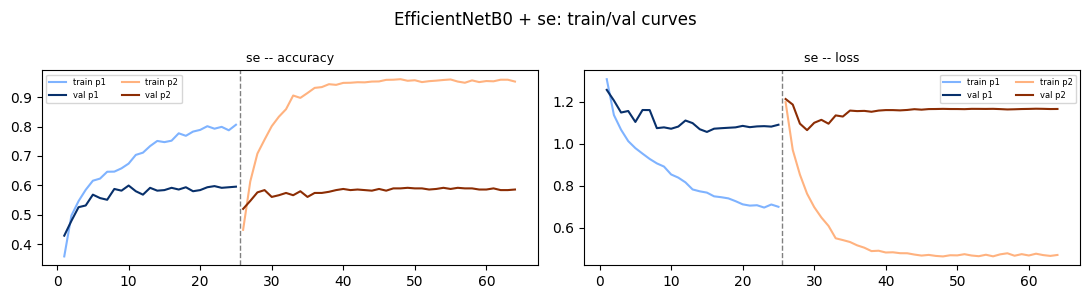

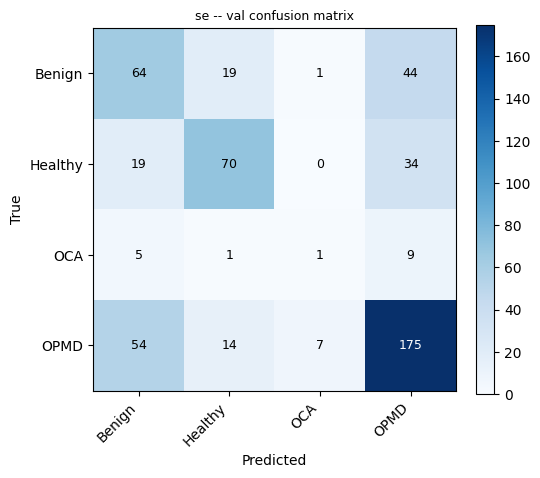

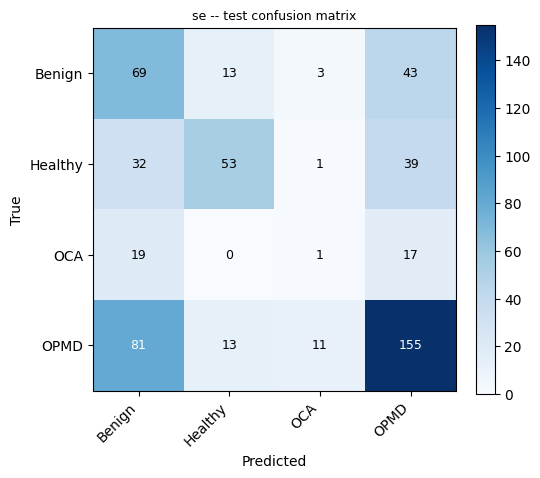

[se] saved embeddings (dim 1280) + class probabilities for every train/val/test image

VARIANT: se_vit_hybrid


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 512 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



[se_vit_hybrid] winning checkpoint: phase1 (frozen)   params=4,691,959   88.0 min
[se_vit_hybrid] train/val gap = 0.1259
[se_vit_hybrid] VAL : accuracy=0.5880  macro_f1=0.4914
[se_vit_hybrid] TEST: accuracy=0.5273  macro_f1=0.4620

TEST classification report:
              precision    recall  f1-score   support

      Benign       0.39      0.48      0.43       128
     Healthy       0.61      0.47      0.53       125
         OCA       0.27      0.27      0.27        37
        OPMD       0.61      0.62      0.61       260

    accuracy                           0.53       550
   macro avg       0.47      0.46      0.46       550
weighted avg       0.54      0.53      0.53       550



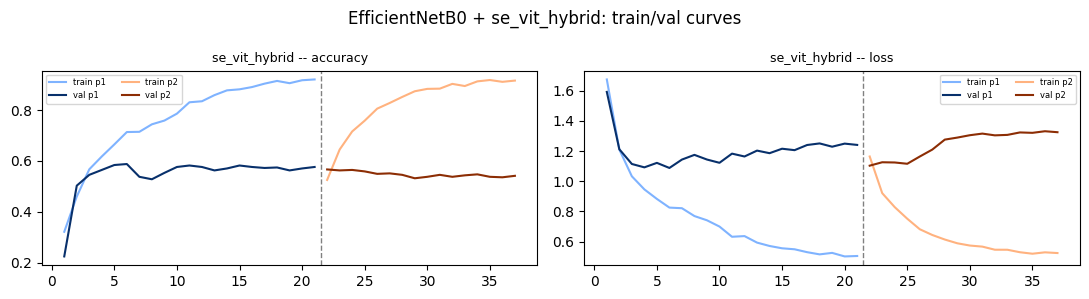

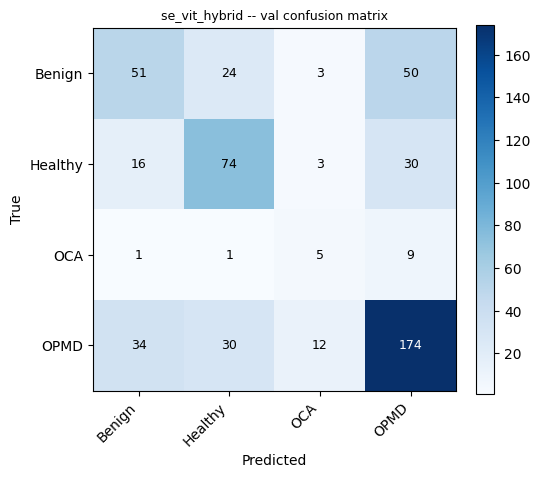

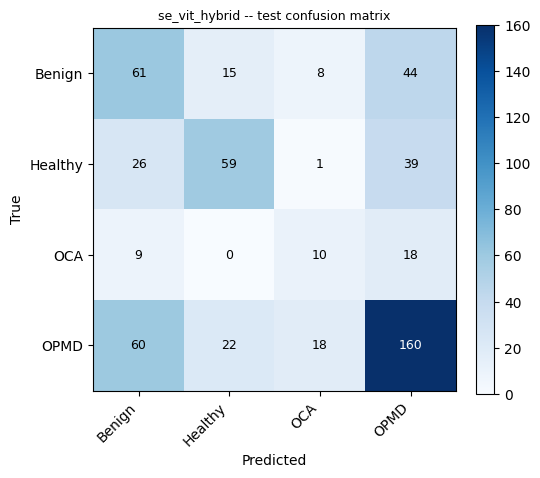

[se_vit_hybrid] saved embeddings (dim 128) + class probabilities for every train/val/test image

VARIANT: axial_hybrid


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 540 variables whereas the saved optimizer has 118 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



[axial_hybrid] winning checkpoint: phase1 (frozen)   params=4,611,879   105.9 min
[axial_hybrid] train/val gap = 0.1758
[axial_hybrid] VAL : accuracy=0.5841  macro_f1=0.4552
[axial_hybrid] TEST: accuracy=0.5273  macro_f1=0.4065

TEST classification report:
              precision    recall  f1-score   support

      Benign       0.37      0.38      0.37       128
     Healthy       0.57      0.38      0.46       125
         OCA       0.14      0.11      0.12        37
        OPMD       0.62      0.73      0.67       260

    accuracy                           0.53       550
   macro avg       0.42      0.40      0.41       550
weighted avg       0.52      0.53      0.52       550



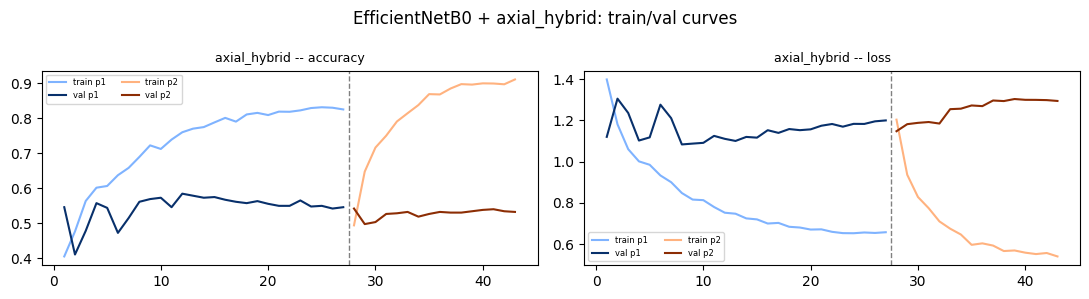

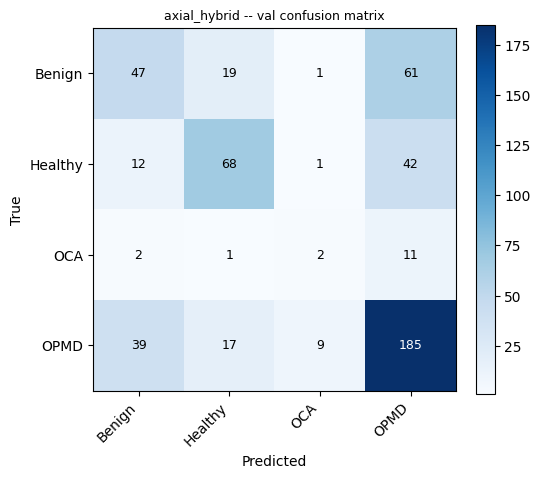

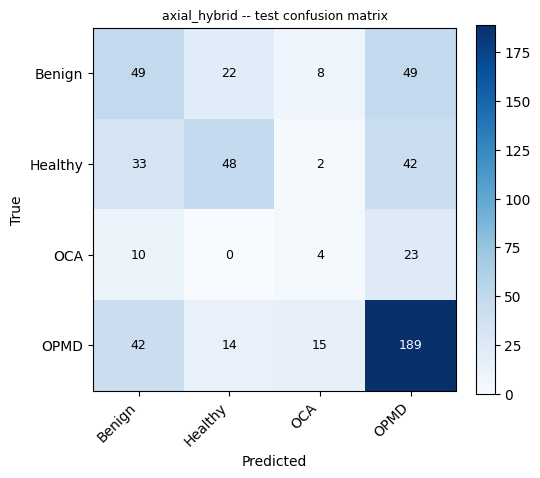

[axial_hybrid] saved embeddings (dim 128) + class probabilities for every train/val/test image

Variants finished in this session: ['se', 'se_vit_hybrid', 'axial_hybrid']


In [4]:
# ============================================================
# 3. TRAIN EVERY SELECTED VARIANT (Stage-5-style two-phase run), evaluate, save embeddings.
#    Val AND test metrics are reported for every variant, but the variant to carry forward is
#    chosen by VAL macro-F1 in the next section -- test is never used for selection.
#    Everything a variant produces is written to disk as soon as it finishes, so an interrupted
#    session keeps the variants already done.
# ============================================================
final_split_root = DATA_VARIANTS[BEST_DATA_VARIANT]
train_ds, val_ds, test_ds, train_raw, CLASS_NAMES_IMG = build_datasets(final_split_root, batch_size=BEST_BATCH_SIZE)
N_CLS = len(CLASS_NAMES_IMG)
class_weight = class_weight_for(train_raw, N_CLS, LOSS_VARIANTS[BEST_LOSS_VARIANT])

# Un-augmented, fixed-order datasets for the embedding files (same procedure as Stage 5).
_emb_sets = []
for _split in ("train", "val", "test"):
    _raw = keras.utils.image_dataset_from_directory(
        final_split_root / _split, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        label_mode="categorical", shuffle=False)
    _emb_sets.append((_split, _raw, _raw.map(preprocess).prefetch(tf.data.AUTOTUNE)))


def extract_and_save_embeddings(model, features, variant):
    # One pass over train/val/test (un-augmented, fixed order) that saves, per image:
    # the embedding vector, and this model's own predicted class probabilities.
    extractor = keras.Model(inputs=model.input, outputs=[features, model.output])
    all_emb, all_prob, all_meta = [], [], []
    for split_name, raw, pp in _emb_sets:
        embs, probs, cats = [], [], []
        for xb, yb in pp:
            f, p = extractor.predict(xb, verbose=0)
            embs.append(f); probs.append(p)
            cats.extend([raw.class_names[i] for i in np.argmax(yb.numpy(), axis=1)])
        all_emb.append(np.concatenate(embs, axis=0))
        all_prob.append(np.concatenate(probs, axis=0))
        all_meta.append(pd.DataFrame({"image_name": [Path(p).stem for p in raw.file_paths],
                                      "category": cats, "split": split_name}))
    emb = np.concatenate(all_emb, axis=0)
    prob = np.concatenate(all_prob, axis=0)
    meta = pd.concat(all_meta, ignore_index=True)
    assert emb.shape[0] == len(meta) == prob.shape[0]
    np.save(OUTPUT_DIR / f"{variant}_embeddings.npy", emb)
    meta.to_csv(OUTPUT_DIR / f"{variant}_embeddings_meta.csv", index=False)
    prob_df = meta.copy()
    for k, c in enumerate(CLASS_NAMES_IMG):
        prob_df[f"prob_{c}"] = prob[:, k]
    prob_df["pred"] = [CLASS_NAMES_IMG[i] for i in np.argmax(prob, axis=1)]
    prob_df.to_csv(OUTPUT_DIR / f"{variant}_probabilities.csv", index=False)
    return emb.shape[1]


def plot_confusion_matrix(y_t, y_p, title, path):
    cm = confusion_matrix(y_t, y_p)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(N_CLS)); ax.set_xticklabels(CLASS_NAMES_IMG, rotation=45, ha="right")
    ax.set_yticks(range(N_CLS)); ax.set_yticklabels(CLASS_NAMES_IMG)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=9)
    for i in range(N_CLS):
        for j in range(N_CLS):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


variant_rows = []
variant_minutes = []
FUSION_MANIFEST = {}
session_t0 = time.time()
for variant in RUN_VARIANTS:
    assert variant in ATTENTION_VARIANTS, f"unknown variant {variant!r}; choose from {ATTENTION_VARIANTS}"
    if variant_minutes:
        remaining = SESSION_BUDGET_MINUTES - (time.time() - session_t0) / 60
        if max(variant_minutes) * 1.1 > remaining:
            print(f"\nStopping before '{variant}': ~{remaining:.0f} min left, a variant needs ~{max(variant_minutes):.0f}. "
                  f"Put the remaining variants in RUN_VARIANTS of a new session.")
            break
    print(f"\n{'=' * 60}\nVARIANT: {variant}\n{'=' * 60}")
    tf.random.set_seed(RANDOM_SEED)
    t0 = time.time()
    result = train_two_phase(f"{BACKBONE_KEY}_{variant}", train_ds, val_ds, class_weight, N_CLS,
                              FINAL_PHASE1_EPOCHS, FINAL_PHASE2_EPOCHS, BEST_PHASE2_LR,
                              dropout_rate=BEST_DROPOUT, weight_decay=BEST_WEIGHT_DECAY,
                              optimizer_name=BEST_OPTIMIZER, variant=variant,
                              early_stop_patience=FINAL_EARLY_STOP_PATIENCE)
    minutes = (time.time() - t0) / 60
    variant_minutes.append(minutes)
    model, features = result["model"], result["features"]

    val_acc, val_f1, val_report, vy, vp = evaluate_split(model, val_ds, N_CLS, CLASS_NAMES_IMG)
    test_acc, test_f1, test_report, ty, tp = evaluate_split(model, test_ds, N_CLS, CLASS_NAMES_IMG)
    n_params = int(model.count_params())
    print(f"\n[{variant}] winning checkpoint: {result['winning_phase']}   params={n_params:,}   {minutes:.1f} min")
    print(f"[{variant}] train/val gap = {result['train_val_gap']:.4f}")
    print(f"[{variant}] VAL : accuracy={val_acc:.4f}  macro_f1={val_f1:.4f}")
    print(f"[{variant}] TEST: accuracy={test_acc:.4f}  macro_f1={test_f1:.4f}")
    print("\nTEST classification report:")
    print(classification_report(ty, tp, target_names=CLASS_NAMES_IMG))

    pd.DataFrame({"true": [CLASS_NAMES_IMG[i] for i in ty], "pred": [CLASS_NAMES_IMG[i] for i in tp]}
                 ).to_csv(OUTPUT_DIR / f"{variant}_test_predictions.csv", index=False)

    plot_grid_curves([result], [f"{variant}"], f"{BB['title']} + {variant}: train/val curves",
                      OUTPUT_DIR / f"{variant}_curves.png")
    plot_confusion_matrix(vy, vp, f"{variant} -- val confusion matrix", OUTPUT_DIR / f"{variant}_val_confusion.png")
    plot_confusion_matrix(ty, tp, f"{variant} -- test confusion matrix", OUTPUT_DIR / f"{variant}_test_confusion.png")

    h1, h2 = result["hist1"].history, result["hist2"].history
    n1 = len(h1["accuracy"])
    pd.DataFrame({"epoch": range(1, n1 + len(h2["accuracy"]) + 1),
                  "phase": [1] * n1 + [2] * len(h2["accuracy"]),
                  "train_accuracy": h1["accuracy"] + h2["accuracy"], "val_accuracy": h1["val_accuracy"] + h2["val_accuracy"],
                  "train_loss": h1["loss"] + h2["loss"], "val_loss": h1["val_loss"] + h2["val_loss"]}
                 ).to_csv(OUTPUT_DIR / f"{variant}_epoch_history.csv", index=False)

    emb_dim = extract_and_save_embeddings(model, features, variant)
    print(f"[{variant}] saved embeddings (dim {emb_dim}) + class probabilities for every train/val/test image")

    # --- everything the fusion models need later, saved per variant ---
    model.save_weights(OUTPUT_DIR / f"{variant}_final.weights.h5")        # the trained image model itself
    for _w in (result["p1_weights"], result["p2_weights"]):                # drop the intermediate checkpoints
        Path(_w).unlink(missing_ok=True)
    _model_cfg = {
        "variant": variant, "backbone": BACKBONE_KEY, "img_size": IMG_SIZE, "class_names": CLASS_NAMES_IMG,
        "dropout_rate": BEST_DROPOUT, "attention": {"d_model": ATTN_D_MODEL, "heads": ATTN_HEADS,
                                                     "layers": ATTN_LAYERS, "dropout": ATTN_DROPOUT, "se_ratio": SE_RATIO},
        "data_variant": BEST_DATA_VARIANT, "embedding_dim": int(emb_dim),
        "rebuild": "model, base, feats = build_attention_model(n_classes, variant, dropout_rate); "
                   "model.load_weights('<variant>_final.weights.h5')  (needs this notebook's section 2 definitions)"}
    with open(OUTPUT_DIR / f"{variant}_model_config.json", "w") as f:
        _json.dump(_model_cfg, f, indent=2)
    FUSION_MANIFEST[variant] = {
        "embeddings_npy": f"{variant}_embeddings.npy", "embeddings_meta_csv": f"{variant}_embeddings_meta.csv",
        "probabilities_csv": f"{variant}_probabilities.csv", "weights": f"{variant}_final.weights.h5",
        "model_config": f"{variant}_model_config.json", "embedding_dim": int(emb_dim),
        "val_macro_f1": round(val_f1, 4), "test_macro_f1": round(test_f1, 4)}
    with open(OUTPUT_DIR / "fusion_manifest.json", "w") as f:
        _json.dump({"class_names": CLASS_NAMES_IMG, "backbone": BACKBONE_KEY, "variants": FUSION_MANIFEST}, f, indent=2)

    row = dict(variant=variant, val_accuracy=round(val_acc, 4), val_macro_f1=round(val_f1, 4),
               test_accuracy=round(test_acc, 4), test_macro_f1=round(test_f1, 4),
               train_val_gap=round(result["train_val_gap"], 4), winning_phase=result["winning_phase"],
               embedding_dim=emb_dim, n_params=n_params, training_minutes=round(minutes, 2))
    variant_rows.append(row)
    pd.DataFrame(variant_rows).to_csv(OUTPUT_DIR / "image_attention_summary.csv", index=False)
    with open(OUTPUT_DIR / f"{variant}_final_metrics.json", "w") as f:
        _json.dump({**row, "backbone": BACKBONE_KEY, "val_report": val_report, "test_report": test_report}, f, indent=2)
    free_run_memory(result)

print("\nVariants finished in this session:", [r["variant"] for r in variant_rows])


FINAL RESULTS (attention models ranked by VALIDATION macro-F1; Stage 5 plain head shown for reference)

             model  val_macro_f1  test_macro_f1  val_accuracy  test_accuracy  train_val_gap  n_params  training_minutes
          SE + ViT        0.4914         0.4620        0.5880         0.5273         0.1259 4691959.0             88.04
                SE        0.4636         0.3950        0.5996         0.5055         0.0745 4260855.0            148.73
             Axial        0.4552         0.4065        0.5841         0.5273         0.1758 4611879.0            105.94
Stage 5 plain head        0.4641         0.5014        0.5899         0.5600         0.3323       NaN               NaN


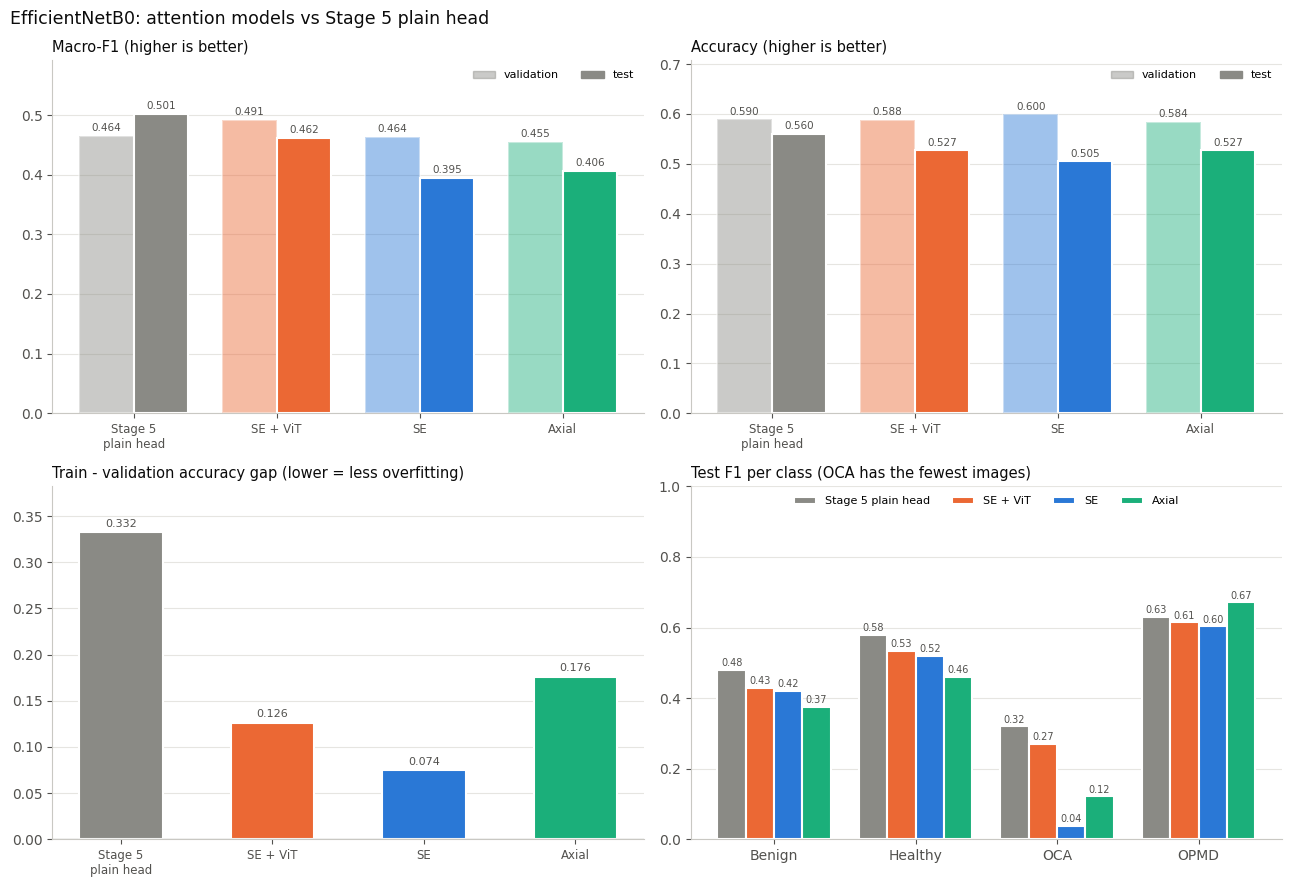

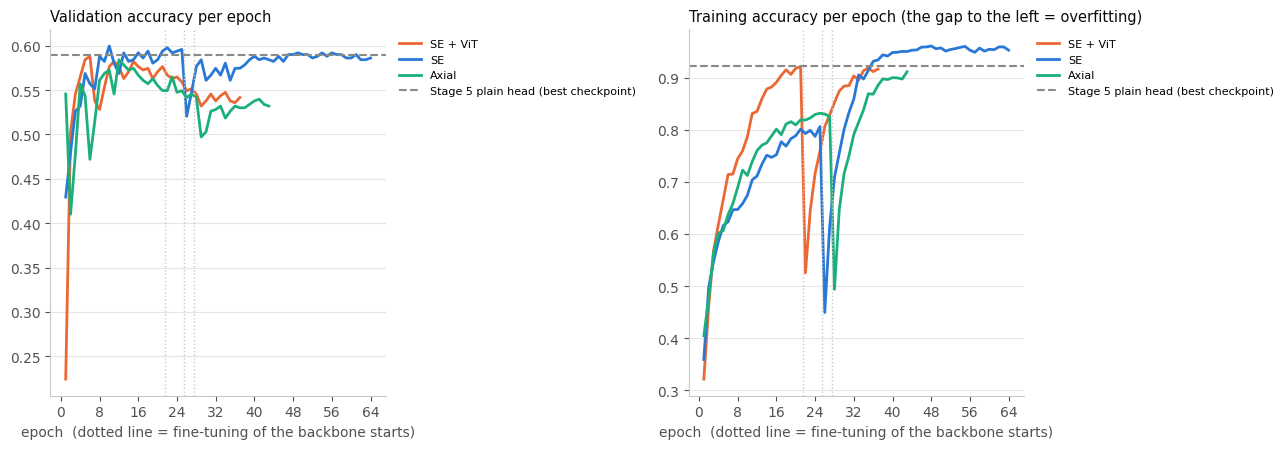

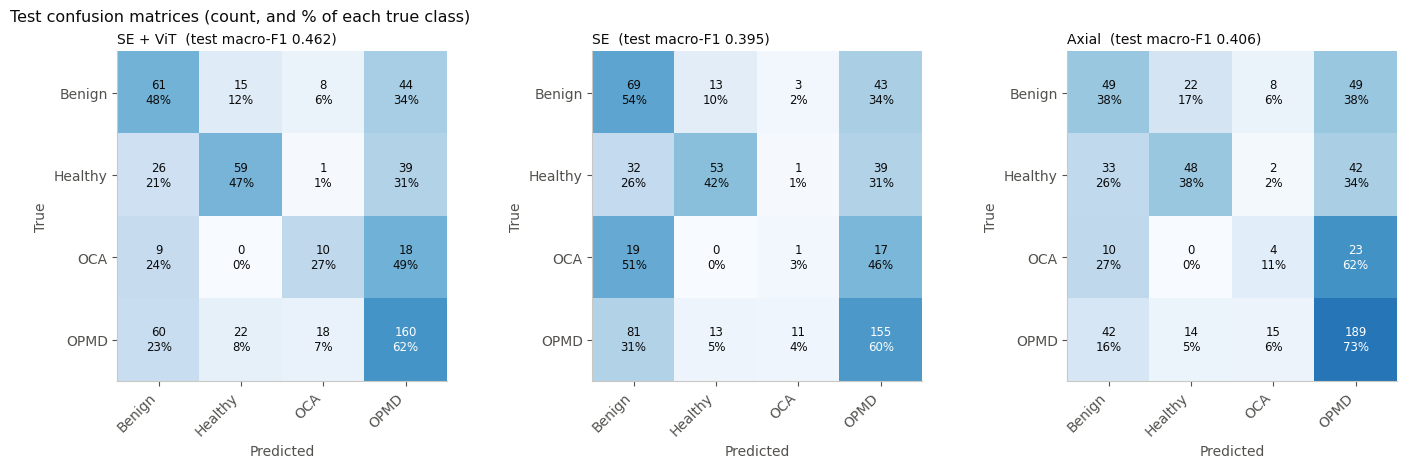


Best attention model by VALIDATION macro-F1: SE + ViT  (se_vit_hybrid)
  validation macro-F1: 0.4914   vs Stage 5 plain head 0.4641   (+0.0273)
  test       macro-F1: 0.4620   vs Stage 5 plain head 0.5014   (-0.0394)
  train/val gap      : 0.1259   vs Stage 5 plain head 0.3323

Caution: the validation set has only 16 'OCA' images, and macro-F1 weights every class equally,
so validation macro-F1 (and therefore this ranking) moves a lot with a handful of 'OCA' predictions.
Each model is ONE training run: differences of ~1-2 points are within run-to-run noise.
If no attention model clearly beats the plain head, that is a valid result: it points to the data
(small classes, overfitting), not the architecture, as the bottleneck.

Embeddings for the fusion notebook: se_vit_hybrid_embeddings.npy + se_vit_hybrid_embeddings_meta.csv
Saved checkpoint.json (Stage 4 values + BEST_ATTENTION_VARIANT) and fusion_manifest.json


In [5]:
# ============================================================
# 4. FINAL RESULTS -- table + graphs for the attention models vs your Stage 5 plain head.
#    The variant to carry forward is chosen by VALIDATION macro-F1 (tie-break: smaller
#    train/val gap). Test numbers are shown for every variant but never used to choose.
# ============================================================
import matplotlib as mpl
import matplotlib.ticker
from sklearn.metrics import confusion_matrix

# ---- 4a. table ---------------------------------------------------------------------------
frames = [pd.DataFrame(variant_rows)]
for p in PREVIOUS_SUMMARY_CSVS:
    if Path(p).is_file():
        frames.append(pd.read_csv(p))
    else:
        print("Warning: previous summary not found:", p)
summary = pd.concat(frames, ignore_index=True).drop_duplicates(subset="variant", keep="first")
summary = summary.sort_values(["val_macro_f1", "train_val_gap"], ascending=[False, True]).reset_index(drop=True)
summary.to_csv(OUTPUT_DIR / "image_attention_summary_all.csv", index=False)

REF = "stage5_plain_head"
LABELS = {"se": "SE", "se_vit_hybrid": "SE + ViT", "axial_hybrid": "Axial", "vit_hybrid": "ViT",
          "cbam": "CBAM", "none": "Plain (re-run)", REF: "Stage 5\nplain head"}
# One fixed color per model (never re-assigned by rank); the reference is neutral grey.
COLORS = {"se": "#2a78d6", "se_vit_hybrid": "#eb6834", "axial_hybrid": "#1baf7a",
          "vit_hybrid": "#e87ba4", "cbam": "#4a3aa7", "none": "#8a8a85", REF: "#8a8a85"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})

ref_row = {"variant": REF, **{k: v for k, v in STAGE5_REFERENCE.items() if not isinstance(v, dict)}}
table = pd.concat([summary, pd.DataFrame([ref_row])], ignore_index=True)
entities = [REF] + list(summary["variant"])            # reference first, then models by validation rank
by_entity = table.set_index("variant")

show = table.copy()
show["model"] = show["variant"].map(lambda v: LABELS[v].replace("\n", " "))
cols = ["model", "val_macro_f1", "test_macro_f1", "val_accuracy", "test_accuracy", "train_val_gap",
        "n_params", "training_minutes"]
print("FINAL RESULTS (attention models ranked by VALIDATION macro-F1; Stage 5 plain head shown for reference)\n")
print(pd.concat([show[show.variant != REF][cols], show[show.variant == REF][cols]]).to_string(index=False))
table.to_csv(OUTPUT_DIR / "image_attention_final_results.csv", index=False)

# ---- 4b. figure 1: metrics ---------------------------------------------------------------
def color_of(e):
    return COLORS.get(e, "#8a8a85")


def grouped_val_test(ax, metric, title):
    x = np.arange(len(entities)); w = 0.38
    cs = [color_of(e) for e in entities]
    vals = [by_entity.loc[e, f"val_{metric}"] for e in entities]
    tests = [by_entity.loc[e, f"test_{metric}"] for e in entities]
    for rects in (ax.bar(x - w / 2, vals, w, color=cs, alpha=0.45, edgecolor="white", linewidth=1.5),
                  ax.bar(x + w / 2, tests, w, color=cs, edgecolor="white", linewidth=1.5)):
        for r in rects:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.005, f"{r.get_height():.3f}",
                    ha="center", va="bottom", fontsize=7.5, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels([LABELS[e] for e in entities], fontsize=8.5)
    ax.set_title(title, fontsize=10.5, loc="left")
    ax.set_ylim(0, max(max(vals), max(tests)) * 1.18)
    ax.grid(axis="x", visible=False)
    ax.legend(handles=[mpl.patches.Patch(color="#8a8a85", alpha=0.45, label="validation"),
                       mpl.patches.Patch(color="#8a8a85", label="test")],
              frameon=False, fontsize=8, loc="upper right", ncol=2)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
grouped_val_test(axes[0, 0], "macro_f1", "Macro-F1 (higher is better)")
grouped_val_test(axes[0, 1], "accuracy", "Accuracy (higher is better)")

ax = axes[1, 0]
gaps = [by_entity.loc[e, "train_val_gap"] for e in entities]
bars = ax.bar(range(len(entities)), gaps, 0.55, color=[color_of(e) for e in entities], edgecolor="white", linewidth=1.5)
span = max(max(gaps) - min(min(gaps), 0), 0.05)
for r in bars:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width() / 2, h + (0.012 * span if h >= 0 else -0.012 * span), f"{h:.3f}",
            ha="center", va="bottom" if h >= 0 else "top", fontsize=8, color=INK2)
ax.axhline(0, color="#c9c8c3", lw=1)
ax.set_ylim(min(min(gaps), 0) - 0.12 * span if min(gaps) < 0 else 0, max(max(gaps), 0) + 0.15 * span)
ax.set_xticks(range(len(entities))); ax.set_xticklabels([LABELS[e] for e in entities], fontsize=8.5)
ax.set_title("Train - validation accuracy gap (lower = less overfitting)", fontsize=10.5, loc="left")
ax.grid(axis="x", visible=False)

# per-class test F1 (only for models trained in THIS session -- their reports are on disk)
ax = axes[1, 1]
f1_by = {REF: [STAGE5_REFERENCE["test_f1_by_class"].get(c, np.nan) for c in CLASS_NAMES_IMG]}
for e in entities[1:]:
    jp = OUTPUT_DIR / f"{e}_final_metrics.json"
    if jp.is_file():
        rep = _json.load(open(jp))["test_report"]
        f1_by[e] = [rep[c]["f1-score"] for c in CLASS_NAMES_IMG]
names = list(f1_by)
w = 0.8 / len(names); xc = np.arange(len(CLASS_NAMES_IMG))
for k, e in enumerate(names):
    rects = ax.bar(xc + (k - (len(names) - 1) / 2) * w, f1_by[e], w, color=color_of(e), edgecolor="white", linewidth=1.5,
                   label=LABELS[e].replace("\n", " "))
    for r in rects:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.005, f"{r.get_height():.2f}",
                ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(xc); ax.set_xticklabels(CLASS_NAMES_IMG)
ax.set_title("Test F1 per class (OCA has the fewest images)", fontsize=10.5, loc="left")
ax.set_ylim(0, 1.0); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=len(names), loc="upper center")
fig.suptitle(f"{BB['title']}: attention models vs Stage 5 plain head", fontsize=12.5, x=0.01, ha="left", color=INK)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "final_fig1_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- 4c. figure 2: learning curves ------------------------------------------------------
curve_models = [e for e in entities[1:] if (OUTPUT_DIR / f"{e}_epoch_history.csv").is_file()]
if curve_models:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=False)
    for ax, col, ttl, ref_val in ((axes[0], "val_accuracy", "Validation accuracy per epoch", STAGE5_REFERENCE["val_accuracy"]),
                                  (axes[1], "train_accuracy", "Training accuracy per epoch (the gap to the left = overfitting)",
                                   STAGE5_REFERENCE["train_accuracy"])):
        for e in curve_models:
            h = pd.read_csv(OUTPUT_DIR / f"{e}_epoch_history.csv")
            ax.plot(h["epoch"], h[col], color=color_of(e), lw=2, label=LABELS[e])
            if (h["phase"] == 2).any():
                ax.axvline(h.loc[h["phase"] == 2, "epoch"].iloc[0] - 0.5, color="#c9c8c3", ls=":", lw=1)
        ax.axhline(ref_val, color="#8a8a85", ls="--", lw=1.5, label="Stage 5 plain head (best checkpoint)")
        ax.set_xlabel("epoch  (dotted line = fine-tuning of the backbone starts)")
        ax.set_title(ttl, fontsize=10.5, loc="left"); ax.grid(axis="x", visible=False)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
        ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "final_fig2_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- 4d. figure 3: test confusion matrices side by side --------------------------------
cm_models = [e for e in entities[1:] if (OUTPUT_DIR / f"{e}_test_predictions.csv").is_file()]
if cm_models:
    fig, axes = plt.subplots(1, len(cm_models), figsize=(4.8 * len(cm_models), 4.6), squeeze=False)
    for ax, e in zip(axes[0], cm_models):
        pr = pd.read_csv(OUTPUT_DIR / f"{e}_test_predictions.csv")
        cm = confusion_matrix(pr["true"], pr["pred"], labels=CLASS_NAMES_IMG)
        norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)          # row-normalised = per-class recall
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(len(CLASS_NAMES_IMG)):
            for j in range(len(CLASS_NAMES_IMG)):
                ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center", fontsize=8.5,
                        color="white" if norm[i, j] > 0.55 else INK)
        ax.set_xticks(range(len(CLASS_NAMES_IMG))); ax.set_xticklabels(CLASS_NAMES_IMG, rotation=45, ha="right")
        ax.set_yticks(range(len(CLASS_NAMES_IMG))); ax.set_yticklabels(CLASS_NAMES_IMG)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.grid(False)
        ax.set_title(f"{LABELS[e]}  (test macro-F1 {by_entity.loc[e, 'test_macro_f1']:.3f})", fontsize=10, loc="left")
    fig.suptitle("Test confusion matrices (count, and % of each true class)", fontsize=11.5, x=0.01, ha="left", color=INK)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "final_fig3_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- 4e. verdict -------------------------------------------------------------------------
best = summary.iloc[0]
b = best["variant"]
ref_val, ref_test = STAGE5_REFERENCE["val_macro_f1"], STAGE5_REFERENCE["test_macro_f1"]
print("\n" + "=" * 70)
print(f"Best attention model by VALIDATION macro-F1: {LABELS[b]}  ({b})")
print(f"  validation macro-F1: {best['val_macro_f1']:.4f}   vs Stage 5 plain head {ref_val:.4f}   "
      f"({best['val_macro_f1'] - ref_val:+.4f})")
print(f"  test       macro-F1: {best['test_macro_f1']:.4f}   vs Stage 5 plain head {ref_test:.4f}   "
      f"({best['test_macro_f1'] - ref_test:+.4f})")
print(f"  train/val gap      : {best['train_val_gap']:.4f}   vs Stage 5 plain head {STAGE5_REFERENCE['train_val_gap']:.4f}")
print("=" * 70)
jp = OUTPUT_DIR / f"{b}_final_metrics.json"
if jp.is_file():
    _vr = _json.load(open(jp))["val_report"]
    _small = min(CLASS_NAMES_IMG, key=lambda c: _vr[c]["support"])
    print(f"\nCaution: the validation set has only {int(_vr[_small]['support'])} '{_small}' images, and macro-F1 weights every class equally,")
    print(f"so validation macro-F1 (and therefore this ranking) moves a lot with a handful of '{_small}' predictions.")
print("Each model is ONE training run: differences of ~1-2 points are within run-to-run noise.")
print("If no attention model clearly beats the plain head, that is a valid result: it points to the data")
print("(small classes, overfitting), not the architecture, as the bottleneck.")
with open(OUTPUT_DIR / "best_variant.json", "w") as f:
    _json.dump({"best_variant_by_val_macro_f1": b,
                "row": {k: (v.item() if hasattr(v, "item") else v) for k, v in best.to_dict().items()}}, f, indent=2)
print(f"\nEmbeddings for the fusion notebook: {b}_embeddings.npy + {b}_embeddings_meta.csv")
_ckpt_out = {**_ckpt, "BEST_ATTENTION_VARIANT": b, "ATTENTION_VARIANTS_COMPARED": list(summary["variant"])}
(OUTPUT_DIR / "checkpoint.json").write_text(_json.dumps(_ckpt_out, indent=2))
print("Saved checkpoint.json (Stage 4 values + BEST_ATTENTION_VARIANT) and fusion_manifest.json")


## Done

**Saved for the fusion models (per variant):** `<variant>_embeddings.npy` + `<variant>_embeddings_meta.csv`
(the fusion notebooks' input), `<variant>_probabilities.csv` (the image model's own class probabilities for
every train/val/test image, for late fusion), `<variant>_final.weights.h5` + `<variant>_model_config.json`
(the trained image model, so it can be rebuilt for end-to-end / joint fusion), and `fusion_manifest.json`
(an index of all of the above). Also per variant: `_curves.png`, `_val_confusion.png`,
`_test_confusion.png`, `_epoch_history.csv`, `_test_predictions.csv`, `_final_metrics.json`. Across variants: `image_attention_summary.csv` (this session),
`image_attention_summary_all.csv` (merged with earlier sessions), `best_variant.json`,
`image_attention_comparison.png`.

Next: run the **fusion-attention notebook** with the best variant's embeddings (and again with the
Stage 5 embeddings for comparison) to see whether better image features and attention-based fusion
help together.
